# 02 · Will this customer churn? Classification, calibration and targeting

*Part 2 of 3 · [README](../README.md) · [01 EDA](01_eda.ipynb) · **02 Modeling** ·
[03 Survival](03_survival.ipynb)*

> **TL;DR.** A tuned LightGBM reaches a held-out ROC-AUC of **0.848** [0.826, 0.868],
> only +0.004 over a logistic-regression baseline in CV, and is already well calibrated.
> Contract, tenure and fiber internet drive the predictions. Targeting customers with
> P(churn) ≥ 0.18 earns about **$51k** of expected profit on 1,409 held-out customers,
> 1.9× the profit of offering everyone the incentive.

This notebook reads the artifacts of the latest training run (`make train`, implemented in
`src/churn/train.py`) and explains them. Nothing here is fit on the test set: every number
is either loaded from `metrics.json` or computed from saved predictions. The only things
computed here are explanations (SHAP) and assumption sensitivity on training data.

**Protocol**

* 80/20 stratified split. The 1,409-customer **test set is used once**, for the final
  numbers.
* On the 5,634 training customers: stratified 5-fold CV to compare a logistic-regression
  baseline against LightGBM. Optuna tunes LightGBM on the same folds.
* All preprocessing (feature engineering, one-hot encoding, scaling) sits inside an sklearn
  `Pipeline`, so it is **refit within every fold**. No statistic of a validation fold ever
  reaches its model.
* Probability calibration (none / Platt / isotonic) is chosen by out-of-fold Brier score
  with nested CV.
* The retention threshold is chosen on out-of-fold training predictions, then applied
  unchanged to the test set.

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by shap
import shap

from churn import business, plots
from churn.config import CONFIG, BusinessConfig, latest_model_dir, set_global_seed
from churn.data import load_clean_data, split_train_test
from churn.evaluate import calibration_table, summarise_cv
from churn.inference import FEATURE_COLUMNS, ChurnPredictor, display_values

plots.apply_style()
pd.set_option("display.precision", 4)

run_dir = latest_model_dir()
metrics = json.loads((run_dir / "metrics.json").read_text())
clf = metrics["classification"]
run = metrics["run"]
print(f"Run {run['version']} | git {run['git_sha'][:7]} | data sha256 {run['data_sha256'][:12]}…")

# The held-out customers, in the same order as the saved test predictions.
test_pred = pd.read_csv(run_dir / "test_predictions.csv")
train_df, test_df = split_train_test(load_clean_data(), CONFIG.split.test_size, CONFIG.seed)
assert (test_df["customerID"].to_numpy() == test_pred["customerID"].to_numpy()).all()

Run 20261028T111359Z-e4e7657 | git e4e7657 | data sha256 16320c9c1ec7…


## 1. Baseline vs LightGBM (5-fold cross-validation on the training set)

In [2]:
names = {
    "logreg": "Logistic regression",
    "lgbm_default": "LightGBM (default)",
    "lgbm_tuned": "LightGBM (Optuna-tuned)",
}
cv_results = pd.read_csv(run_dir / "cv_results.csv")
summary = summarise_cv(cv_results)
table = pd.DataFrame(
    {
        metric: summary[metric]["mean"].map("{:.3f}".format)
        + " ± "
        + summary[metric]["std"].map("{:.3f}".format)
        for metric in ["roc_auc", "pr_auc", "brier", "log_loss"]
    }
).rename(
    index=names,
    columns={
        "roc_auc": "ROC-AUC ↑",
        "pr_auc": "PR-AUC ↑",
        "brier": "Brier ↓",
        "log_loss": "Log loss ↓",
    },
)
table

,ROC-AUC ↑,PR-AUC ↑,Brier ↓,Log loss ↓
model,,,,
Logistic regression,0.846 ± 0.014,0.659 ± 0.021,0.135 ± 0.006,0.417 ± 0.014
LightGBM (default),0.835 ± 0.009,0.637 ± 0.027,0.142 ± 0.007,0.439 ± 0.016
LightGBM (Optuna-tuned),0.850 ± 0.013,0.667 ± 0.022,0.134 ± 0.006,0.412 ± 0.014


In [3]:
paired = cv_results.pivot(index="fold", columns="model", values="roc_auc")
delta = paired["lgbm_tuned"] - paired["logreg"]
print(
    f"Tuned LightGBM minus logistic regression, ROC-AUC per fold: {np.round(delta.to_numpy(), 4)}\n"
    f"mean {delta.mean():+.4f}; LightGBM wins {int((delta > 0).sum())} of {len(delta)} folds"
)

Tuned LightGBM minus logistic regression, ROC-AUC per fold: [-0.0037  0.0085  0.0049  0.0001  0.0104]
mean +0.0040; LightGBM wins 4 of 5 folds


* **Default LightGBM loses to the linear baseline** (0.835 vs 0.846 ROC-AUC). With
  ~5.6k rows and a few strong, mostly monotonic drivers, an unregularised 100-tree,
  31-leaf boosted model overfits.
* **Tuning recovers and slightly exceeds the baseline**: 0.850 ROC-AUC, ahead of logistic
  regression in 4 of 5 folds and by +0.004 on average. It is best on all four metrics,
  so it becomes the champion. The tuned configuration is very constrained (5 leaves, ≥160 samples
  per leaf, 200 trees), which is close to an additive model. That is consistent with the
  linear model already being competitive.
* The tuned model's CV score is slightly optimistic, because Optuna picked it using these
  same folds. The held-out test set in section 4 is the unbiased check.
* Honest reading: the margin over a well-specified logistic regression is small. Most of
  the value in this project comes from the probability quality and the decision layer,
  not from the choice of algorithm.

## 2. Hyperparameter search (Optuna, small budget)

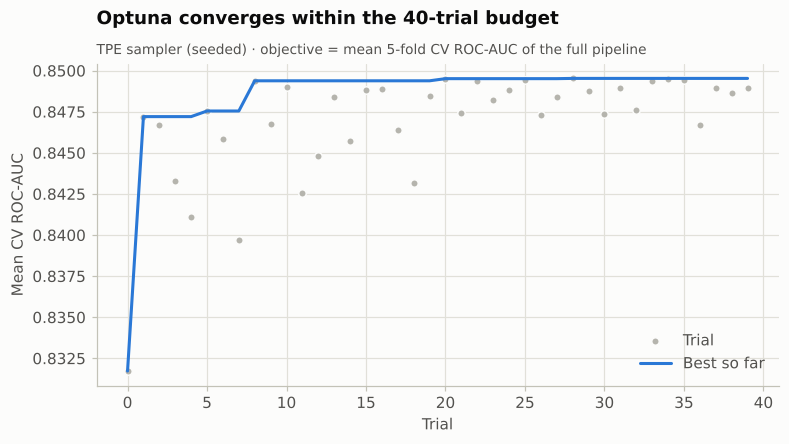

,best value
n_estimators,200
learning_rate,0.0324
num_leaves,5
min_child_samples,163
subsample,0.6162
colsample_bytree,0.6748
reg_lambda,1.2016
reg_alpha,0.0086
subsample_freq,1


In [4]:
trials = pd.read_csv(run_dir / "optuna_trials.csv")
fig, ax = plt.subplots(figsize=(8, 3.8))
plots.plot_optuna_history(trials, ax=ax)
plots.set_title(
    ax,
    "Optuna converges within the 40-trial budget",
    "TPE sampler (seeded) · objective = mean 5-fold CV ROC-AUC of the full pipeline",
)
plots.save_figure(fig, "optuna_history")
plt.show()

pd.Series(
    {
        k: round(v, 4) if isinstance(v, float) else v
        for k, v in clf["tuning"]["best_params"].items()
    },
    name="best value",
    dtype=object,
).to_frame()

## 3. Probability calibration

The business layer multiplies probabilities by revenue, so they must mean what they say:
among customers given 30%, about 30% should churn. Three options were compared with
**nested CV**: the uncalibrated champion, Platt scaling (sigmoid) and isotonic regression.
Each calibrator is fitted with an inner 5-fold `CalibratedClassifierCV`, so the
calibration map is never learnt on rows the model was trained on.

In [5]:
oof = pd.read_csv(run_dir / "oof_predictions.csv")
labels = {"none": "Uncalibrated", "sigmoid": "Platt (sigmoid)", "isotonic": "Isotonic"}
oof_brier = pd.Series(clf["calibration"]["oof_brier"]).rename(index=labels)
print(f"Selected: {labels[clf['calibration']['selected']]}")
pd.DataFrame(
    {
        "out-of-fold Brier ↓": oof_brier.map("{:.5f}".format),
        "difference vs uncalibrated": (oof_brier - oof_brier.iloc[0]).map("{:+.5f}".format),
    }
)

Selected: Uncalibrated


,out-of-fold Brier ↓,difference vs uncalibrated
Uncalibrated,0.13367,+0.00000
Platt (sigmoid),0.13375,+0.00007
Isotonic,0.13377,+0.00010


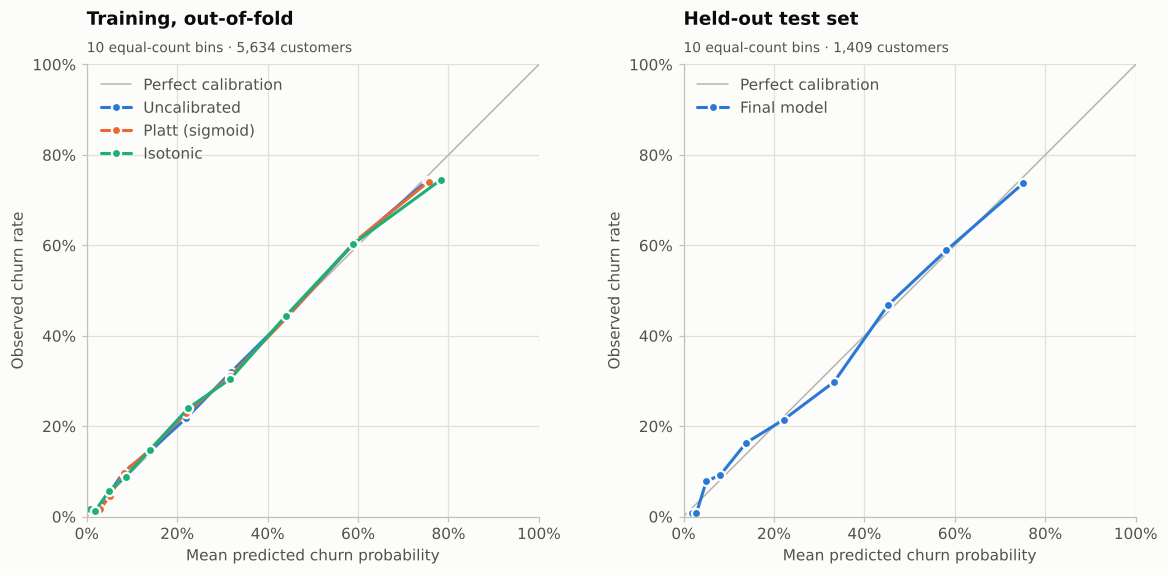

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
plots.plot_reliability(
    {
        labels[m]: calibration_table(oof["Churn"], oof[f"p_{m}"])
        for m in ["none", "sigmoid", "isotonic"]
    },
    ax=axes[0],
)
plots.set_title(axes[0], "Training, out-of-fold", "10 equal-count bins · 5,634 customers")
plots.plot_reliability(
    {"Final model": calibration_table(test_pred["Churn"], test_pred["p_churn"])}, ax=axes[1]
)
plots.set_title(axes[1], "Held-out test set", "10 equal-count bins · 1,409 customers")
fig.tight_layout()
plots.save_figure(fig, "calibration")
plt.show()

The champion is **already well calibrated**. LightGBM optimises log loss, a proper
scoring rule, and we deliberately did not re-weight classes. Neither Platt scaling nor
isotonic regression lowers the out-of-fold Brier score (all three differ by < 0.0001),
and the reliability curves overlap the diagonal. The pipeline therefore keeps the
uncalibrated model, the simplest option at equal quality. Isotonic regression in
particular adds variance when each fold has only ~1,100 rows to calibrate on.

Calibration is still a selectable step in the pipeline (`ClassificationConfig.calibration_methods`).
If a future model is miscalibrated, the same selection logic will choose Platt or isotonic.

## 4. Held-out test performance

95% confidence intervals come from 1,000 bootstrap resamples of the test set.

In [7]:
final = clf["test"]["final"]
pd.DataFrame(
    {
        "value": {k: v["value"] for k, v in final.items()},
        "95% CI": {k: f"[{v['ci_low']:.3f}, {v['ci_high']:.3f}]" for k, v in final.items()},
        "CV mean (train)": {k: clf["cv"][clf["champion"]][k]["mean"] for k in final},
    }
).rename(
    index={"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier score", "log_loss": "Log loss"}
)

,value,95% CI,CV mean (train)
ROC-AUC,0.8476,"[0.826, 0.868]",0.8495
PR-AUC,0.6665,"[0.616, 0.713]",0.6670
Brier score,0.1345,"[0.124, 0.144]",0.1337
Log loss,0.4137,"[0.387, 0.440]",0.4122


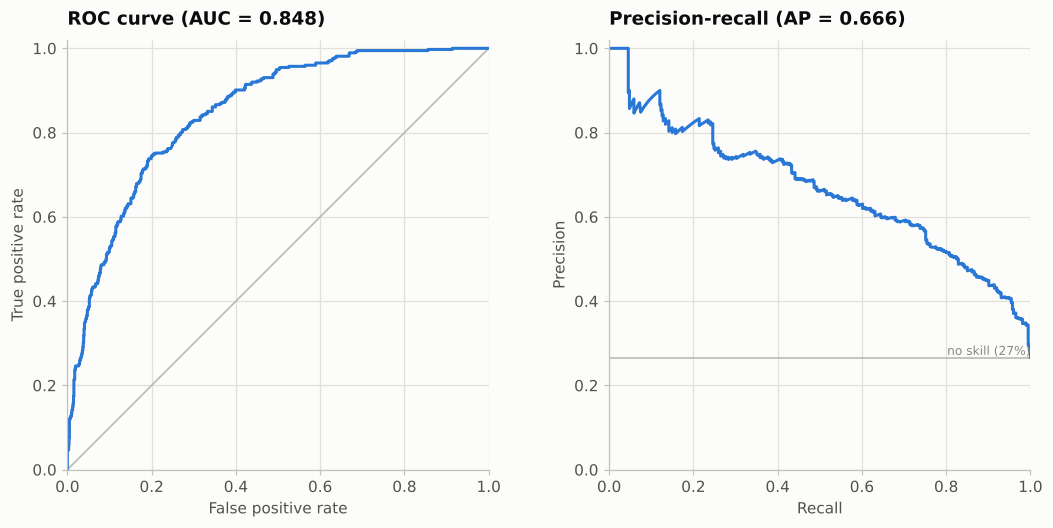

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
plots.plot_roc_pr(test_pred["Churn"], test_pred["p_churn"], axes)
axes[0].set_title(f"ROC curve (AUC = {final['roc_auc']['value']:.3f})")
fig.tight_layout()
plots.save_figure(fig, "roc_pr_test")
plt.show()

Test performance (ROC-AUC 0.848, PR-AUC 0.666) matches cross-validation, so the model
generalises and the tuning optimism was negligible. For context, the no-skill PR-AUC is
the churn rate, 0.265.

### Across customer groups

Aggregate metrics can hide groups the model serves worse. Below, the same test-set
metrics are shown per gender, senior status and contract. "Mean predicted" vs "churn
rate" checks calibration within the group, and "targeted" is the share above the 0.18
threshold.

In [9]:
from sklearn.metrics import brier_score_loss, roc_auc_score

from churn.config import CATEGORY_LEVELS

scored = test_df.assign(p_churn=test_pred["p_churn"].to_numpy())
rows = []
for attribute in ["gender", "SeniorCitizen", "Contract"]:
    for level in CATEGORY_LEVELS[attribute]:
        g = scored[scored[attribute] == level]
        rows.append(
            {
                "attribute": attribute,
                "group": level,
                "customers": len(g),
                "churn rate": f"{g['Churn'].mean():.1%}",
                "mean predicted": f"{g['p_churn'].mean():.1%}",
                "ROC-AUC": f"{roc_auc_score(g['Churn'], g['p_churn']):.3f}",
                "Brier": f"{brier_score_loss(g['Churn'], g['p_churn']):.3f}",
                "targeted": f"{(g['p_churn'] >= metrics['business']['threshold']).mean():.0%}",
            }
        )
pd.DataFrame(rows).set_index(["attribute", "group"])

customers churn rate mean predicted ROC-AUC  \
attribute     group                                                         
gender        Female                687      28.1%          26.6%   0.846   
              Male                  722      25.1%          26.5%   0.850   
SeniorCitizen No                   1187      23.3%          24.0%   0.849   
              Yes                   222      44.1%          40.5%   0.787   
Contract      Month-to-month        773      42.6%          43.0%   0.758   
              One year              300      12.0%          10.1%   0.749   
              Two year              336       2.7%           3.5%   0.731   

                              Brier targeted  
attribute     group                           
gender        Female          0.139      50%  
              Male            0.130      50%  
SeniorCitizen No              0.125      45%  
              Yes             0.187      77%  
Contract      Month-to-month  0.196      84%  
              One year        0.098      18%  
              Two year        0.026       0%

* **Gender: no gap.** ROC-AUC 0.846 vs 0.850, calibration within 1.5 points, and the
  same share of each group is targeted (about 50%). This matches gender's near-zero SHAP
  importance below.
* **Senior citizens** are ranked less well (0.787 vs 0.849, on only 222 customers) and
  slightly under-predicted (44% observed vs 41% predicted). They are targeted more often
  (77% vs 45%) because their churn rate really is higher, not because of a modelling
  artefact. Still, this is the group to monitor first in production.
* **Within a contract type**, ranking drops to 0.73-0.76. Part of the overall 0.848 comes
  from separating month-to-month customers from contract holders. Within each segment
  the probabilities remain well calibrated, which is what the profit calculation needs.

## 5. What drives the predictions? SHAP explanations

SHAP values decompose each prediction (in log-odds) into additive feature
contributions. They are computed for the champion pipeline refit on the full training
set, which is the deployed model because no calibration was applied. If a calibrator were
selected it would be a monotonic map on top, so the ranking of drivers would be the same.
Features are those the model sees after preprocessing: one-hot dummies plus unscaled
numeric columns, so values stay readable.

In [10]:
champion = joblib.load(run_dir / "base_classifiers.joblib")[clf["champion"]]
X_test = champion["preprocess"].transform(test_df)
model = champion["model"]

if clf["champion"].startswith("lgbm"):
    explainer = shap.TreeExplainer(model)
    raw = model.predict(X_test, raw_score=True)
else:  # logistic regression champion
    explainer = shap.LinearExplainer(model, champion["preprocess"].transform(train_df))
    raw = model.decision_function(X_test)
sv = explainer(X_test)
print(
    "Additivity check (base value + contributions = model log-odds):",
    np.allclose(sv.base_values + sv.values.sum(axis=1), raw),
)

Additivity check (base value + contributions = model log-odds): True


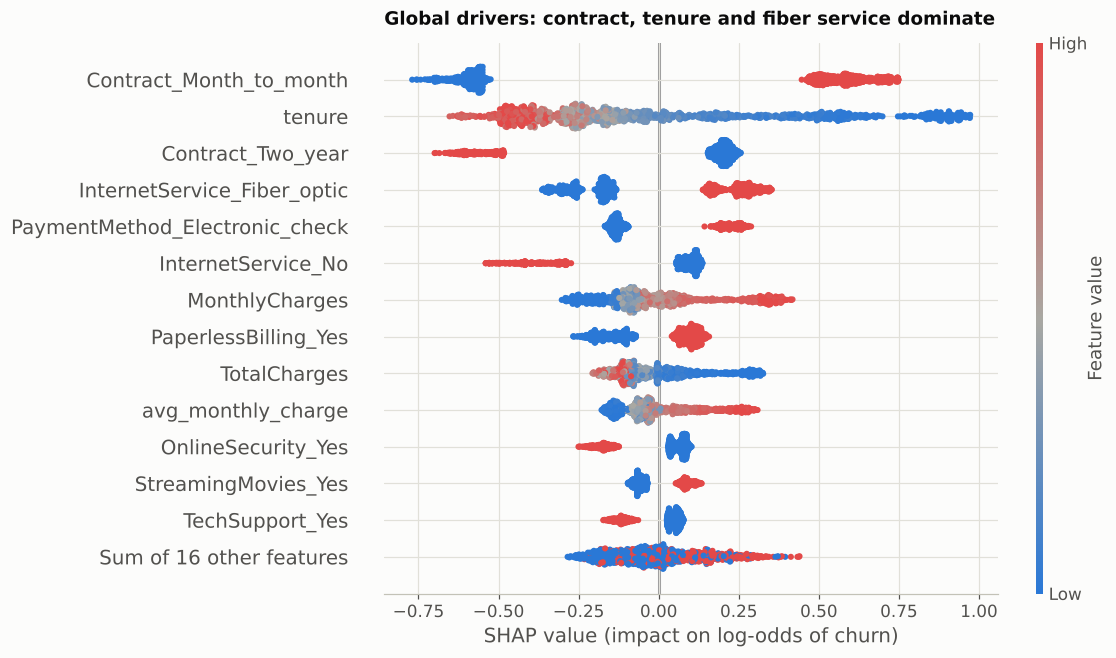

In [11]:
set_global_seed()  # the beeswarm jitters dots with NumPy's global RNG: keep the figure reproducible
shap.plots.beeswarm(
    sv,
    max_display=14,
    color=plots.DIVERGING_CMAP,
    show=False,
    plot_size=(9, 6.5),
    axis_color=plots.INK_2,
)
fig = plt.gcf()
fig.axes[0].set_title(
    "Global drivers: contract, tenure and fiber service dominate", loc="left", pad=12
)
fig.axes[0].set_xlabel("SHAP value (impact on log-odds of churn)")
plots.save_figure(fig, "shap_global")
plt.show()

In [12]:
importance = (
    pd.DataFrame({"mean |SHAP|": np.abs(sv.values).mean(axis=0)}, index=X_test.columns)
    .sort_values("mean |SHAP|", ascending=False)
    .head(10)
)
importance["share of total"] = (
    importance["mean |SHAP|"] / np.abs(sv.values).mean(axis=0).sum()
).map("{:.0%}".format)
importance

,mean |SHAP|,share of total
Contract_Month_to_month,0.5887,21%
tenure,0.3577,13%
Contract_Two_year,0.2891,10%
InternetService_Fiber_optic,0.2312,8%
PaymentMethod_Electronic_check,0.1635,6%
InternetService_No,0.1612,6%
MonthlyCharges,0.1359,5%
PaperlessBilling_Yes,0.1193,4%
TotalCharges,0.1043,4%
avg_monthly_charge,0.0979,3%


SHAP values are additive, so summing each customer's values over the dummies of one
attribute gives that attribute's total contribution. Ranking *attributes* (not levels)
is what a business reader usually wants:

In [13]:
# The same scoring code the API and the app use (churn.inference.ChurnPredictor).
predictor = ChurnPredictor.load(run_dir)
X = predictor.prepare(test_df[FEATURE_COLUMNS])
_, by_attribute = predictor.explain(X)
attribute_importance = by_attribute.abs().mean().sort_values(ascending=False)
(attribute_importance / attribute_importance.sum()).head(10).map("{:.0%}".format).to_frame(
    "share of mean |SHAP|"
)

,share of mean |SHAP|
Contract,30%
tenure,14%
InternetService,13%
PaymentMethod,6%
MonthlyCharges,5%
PaperlessBilling,5%
TotalCharges,4%
avg_monthly_charge,4%
OnlineSecurity,4%
StreamingMovies,3%


* **Month-to-month contracts** are the largest driver: being on one pushes the log-odds
  up, and longer contracts push them down.
* **Tenure** has a strong, monotone effect. New customers are at much higher risk, which
  matches the Kaplan-Meier curves in notebook 01.
* **Fiber-optic internet** raises risk despite being the premium product. Together with
  higher `MonthlyCharges`, this points to a price/value perception problem worth a
  follow-up with the product team.
* **Electronic-check payment** and **paperless billing** add risk. **Online security**
  (#11) and **tech support** (#13) are protective but second-order. These are actionable
  levers: auto-pay migration and bundling support services are natural retention offers.
* Demographics matter little. `gender` is close to zero, and `SeniorCitizen`'s high raw
  churn rate (42%) is mostly explained by the attributes above.

SHAP shows association, not causation. Contract type is partly an *outcome* of a
customer's intent to stay, so "move everyone to two-year contracts" is not a valid
conclusion from this chart alone.

### Local explanations: why *this* customer?

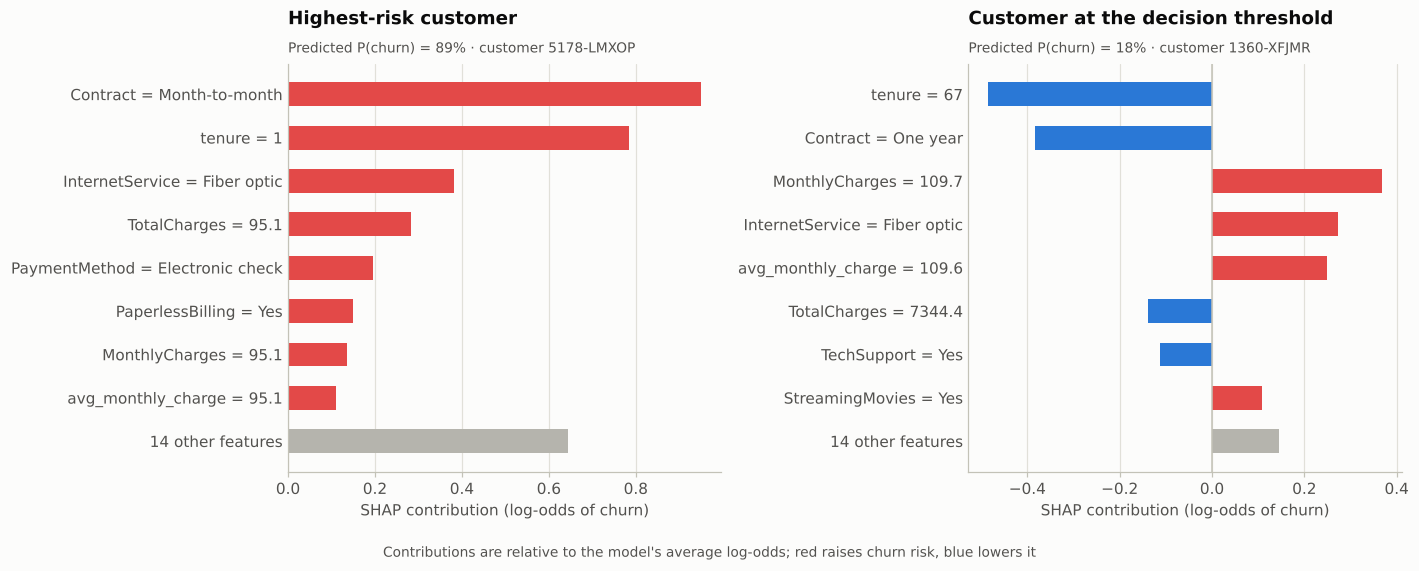

In [14]:
threshold = metrics["business"]["threshold"]
highest = int(test_pred["p_churn"].idxmax())
borderline = int((test_pred["p_churn"] - threshold).abs().idxmin())

values = display_values(X)  # raw categories and readable numeric inputs per attribute

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, idx, label in [
    (axes[0], highest, "Highest-risk customer"),
    (axes[1], borderline, "Customer at the decision threshold"),
]:
    plots.plot_local_explanation(by_attribute.iloc[idx], values.iloc[idx], ax=ax, top_k=8)
    row = test_pred.iloc[idx]
    plots.set_title(
        ax, label, f"Predicted P(churn) = {row['p_churn']:.0%} · customer {row['customerID']}"
    )
fig.supxlabel(
    "Contributions are relative to the model's average log-odds; red raises churn risk, blue lowers it",
    fontsize=9,
    color=plots.INK_2,
)
fig.tight_layout()
plots.save_figure(fig, "shap_local")
plt.show()

Dummies are summed back to their attribute, so each bar is one business attribute. The
left customer is a textbook high-risk profile: one month in, month-to-month, fiber
internet, paying by electronic check. The right customer sits exactly at the threshold.
Long tenure (67 months) and a one-year contract protect them, but a $110 fiber bill pushes
risk back up. When risk and protective factors roughly cancel like this, the offer
economics, not the model, should make the call.

## 6. From probabilities to a retention decision

**Assumptions** (all in `churn.config.BusinessConfig`; they are assumptions, not data):

In [15]:
biz = metrics["business"]
assumptions = biz["assumptions"]
pd.Series(
    {
        "Value horizon": f"{assumptions['horizon_months']} months of MonthlyCharges",
        "Offer cost per targeted customer": f"${assumptions['offer_cost']:.0f}",
        "Offer success rate (would-be churner retained)": f"{assumptions['offer_success_rate']:.0%}",
    },
    name="assumption",
).to_frame()

,assumption
Value horizon,12 months of MonthlyCharges
Offer cost per targeted customer,$50
Offer success rate (would-be churner retained),30%


**Revenue at risk** = P(churn) × MonthlyCharges × 12. It is the expected revenue the
test-set customers will take with them if nothing is done:

In [16]:
rar = test_pred["revenue_at_risk"].sort_values(ascending=False)
top20 = rar.head(int(0.2 * len(rar))).sum() / rar.sum()
print(
    f"Revenue at risk, test set (1,409 customers): ${rar.sum():,.0f} over 12 months\n"
    f"Top 20% of customers by revenue at risk hold {top20:.0%} of it"
)

Revenue at risk, test set (1,409 customers): $330,806 over 12 months
Top 20% of customers by revenue at risk hold 57% of it


**Expected profit** of targeting every customer with P(churn) ≥ *t*:

$$\text{profit}(t) = \sum_{i:\,p_i \ge t} \big(\, y_i \cdot s \cdot 12\,m_i \;-\; c \,\big)$$

Here *y* is whether the customer churns, *s* the offer success rate, *m* the monthly
charge and *c* the offer cost. The threshold is chosen on **out-of-fold training
predictions** and then evaluated on the test set.

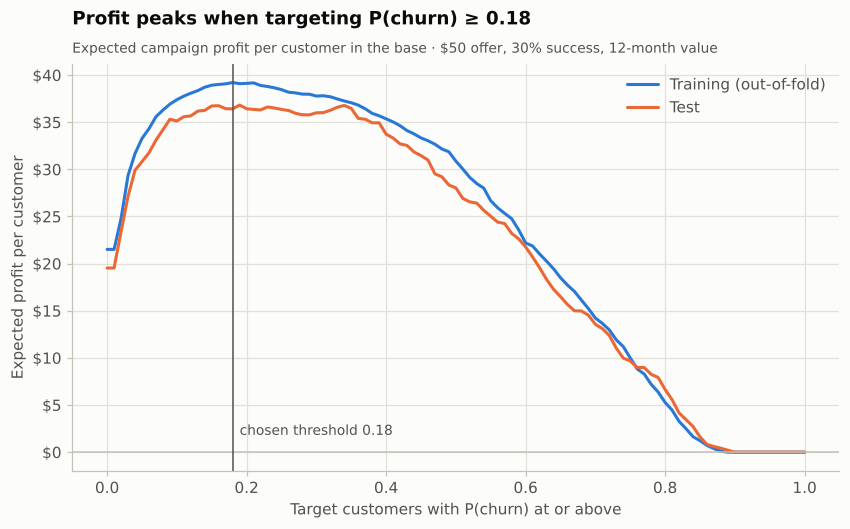

In [17]:
curve_oof = pd.read_csv(run_dir / "profit_curve_oof.csv")
curve_test = pd.read_csv(run_dir / "profit_curve_test.csv")

fig, ax = plt.subplots(figsize=(9, 4.8))
plots.plot_profit_curves(
    {"Training (out-of-fold)": curve_oof, "Test": curve_test}, threshold, ax=ax
)
plots.set_title(
    ax,
    f"Profit peaks when targeting P(churn) ≥ {threshold:.2f}",
    "Expected campaign profit per customer in the base · $50 offer, 30% success, 12-month value",
)
plots.save_figure(fig, "profit_curve")
plt.show()

In [18]:
t = biz["test"]
policies = pd.DataFrame(
    [
        ("Do nothing", 0, 0, 0.0),
        ("Target everyone", t["n_customers"], t["churners_total"], t["profit_target_everyone"]),
        (
            f"Model, threshold {threshold:.2f} (chosen on training)",
            t["n_targeted"],
            t["churners_reached"],
            t["profit"],
        ),
        (
            "Model, per-customer breakeven (value-aware)",
            t["value_aware_n_targeted"],
            t["value_aware_churners_reached"],
            t["value_aware_profit"],
        ),
        (
            f"Hindsight-best threshold {t['hindsight_best_threshold']:.2f} (not achievable)",
            None,
            None,
            t["hindsight_best_profit"],
        ),
    ],
    columns=["policy (test set)", "customers targeted", "churners reached", "expected profit"],
).set_index("policy (test set)")
policies["expected profit"] = policies["expected profit"].map("${:,.0f}".format)
for col in ["customers targeted", "churners reached"]:
    policies[col] = policies[col].map(lambda v: "—" if pd.isna(v) else f"{int(v):,}")
policies

,customers targeted,churners reached,expected profit
policy (test set),,,
Do nothing,0,0,$0
Target everyone,"1,409",374,"$27,524"
"Model, threshold 0.18 (chosen on training)",701,325,"$51,313"
"Model, per-customer breakeven (value-aware)",614,294,"$53,338"
Hindsight-best threshold 0.19 (not achievable),—,—,"$51,884"


On the 1,409 test customers:

* The chosen threshold (0.18) targets about **half the base** and reaches **87% of
  churners** (325 of 374). It earns about **$51k**, nearly double the $28k of
  targeting everyone and 99% of the best threshold in hindsight. So threshold selection on
  training data transferred well.
* The model-based forecast of this profit, using predicted probabilities in place of
  outcomes, was $54k. That is close to the realised $51k, another sign the probabilities
  are calibrated.
* The threshold is low because the offer is cheap relative to a year of revenue
  ($50 vs ~$780). Breakeven for an average customer is P(churn) ≈ 21%.
* **A value-aware rule does better.** Targeting a customer when *their own* expected
  profit is positive (P(churn) > c / (s · 12 · m)) earns about $2k more with ~90 fewer
  offers. It skips low-bill customers who are not worth the offer and includes high-bill
  ones at lower risk. This is the recommended policy to evaluate next.

### How sensitive is the decision to the assumptions?

In [19]:
oof_charges = train_df.set_index("customerID").loc[oof["customerID"], "MonthlyCharges"].to_numpy()
rows = []
for cost in [25, 50, 75, 100]:
    for success in [0.15, 0.30, 0.45]:
        cfg = BusinessConfig(horizon_months=12, offer_cost=cost, offer_success_rate=success)
        best = business.optimal_threshold(
            business.profit_curve(oof["Churn"], oof["p_churn"], oof_charges, cfg=cfg)
        )
        rows.append(
            {
                "offer cost": f"${cost}",
                "success rate": f"{success:.0%}",
                "cell": f"t = {best['threshold']:.2f} · target {best['share_targeted']:.0%}",
            }
        )
pd.DataFrame(rows).pivot(index="offer cost", columns="success rate", values="cell").loc[
    ["$25", "$50", "$75", "$100"]
]

success rate,15%,30%,45%
offer cost,,,
$25,t = 0.18 · target 50%,t = 0.09 · target 63%,t = 0.05 · target 75%
$50,t = 0.40 · target 28%,t = 0.18 · target 50%,t = 0.14 · target 55%
$75,t = 0.49 · target 22%,t = 0.35 · target 32%,t = 0.18 · target 50%
$100,t = 0.72 · target 7%,t = 0.40 · target 28%,t = 0.32 · target 35%


Each cell shows the profit-maximising threshold and the share of customers it targets,
computed on out-of-fold training predictions. Cheaper or more effective offers justify
broader campaigns. The ranking is unchanged: the model decides *who*, and the
assumptions decide *how many*. Since the success rate is the most uncertain input, the
first campaign should be run as an **A/B test** that measures it, using a randomised
hold-out among targeted customers.

## 7. Summary

| | |
|---|---|
| Champion | LightGBM (Optuna-tuned), uncalibrated (already well calibrated) |
| Test ROC-AUC / PR-AUC / Brier | 0.848 [0.826, 0.868] / 0.666 / 0.135 |
| Baseline (logistic regression, CV) | 0.846 ROC-AUC: a strong baseline, so the margin is small |
| Top drivers | contract type, tenure, fiber internet, monthly charges, payment method |
| Decision | target P(churn) ≥ 0.18 → ~50% of base, 87% of churners, ≈$51k expected profit per 1.4k customers |
| Next step | value-aware targeting (+$2k on test) and an A/B test to measure offer success rate |